# Telecom Customer Churn Analysis & Retention Strategy

**Author:** Rumbidzai Mahlanganise · **Tools:** Python (pandas, matplotlib, scikit-learn), SQL (SQLite)

## Business problem
A telecom provider is losing customers every month. Each customer who leaves takes their monthly revenue with them, and winning new customers costs more than keeping existing ones. The retention team wants to know **who is leaving, why, and who to contact first**.

## Questions this analysis answers
1. How many customers churn, and how much monthly revenue is lost?
2. Which customer groups churn most (contract, tenure, internet service, payment method, support services)?
3. Which factors still matter once everything is considered together?
4. Can we rank customers by churn risk so the retention team targets the right people?
5. What should the business do about it?

## Data
IBM **Telco Customer Churn** sample dataset: 7,043 customers of a fictional telecom company, one row per customer, with demographics, account details, services and whether they left in the last month (`Churn`).
Source: [IBM / telco-customer-churn-on-icp4d](https://github.com/IBM/telco-customer-churn-on-icp4d) (Apache License 2.0).

In [1]:
import json, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, confusion_matrix

pd.set_option('display.max_columns', 30)

# Chart style: one consistent, colour-blind-safe palette for every figure
CHURN, STAY = '#D55E2B', '#0A8F86'          # orange = churned / raises risk, teal = stayed / lowers risk
INK, MUTED, GRID, REF = '#0F1E2E', '#56677A', '#E2E8EE', '#8796A5'
plt.rcParams.update({
    'font.family': 'Inter', 'font.size': 11, 'axes.edgecolor': '#C9D2DB', 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})
IMG = '../images/'

def headline(ax, title, subtitle):
    ax.set_title(title, loc='left', fontsize=14.5, fontweight='semibold', color=INK, pad=30)
    ax.text(0, 1.035, subtitle, transform=ax.transAxes, fontsize=10.5, color=MUTED, va='bottom')

## 1. Load and inspect the data

In [2]:
raw = pd.read_csv('../data/Telco-Customer-Churn.csv')
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Data quality checks
print('Duplicate customer IDs:', raw['customerID'].duplicated().sum())
print('Missing values per column:', int(raw.isna().sum().sum()))
blank_total = raw['TotalCharges'].str.strip().eq('')
print('Blank TotalCharges values:', blank_total.sum())
print('Tenure of those customers:', raw.loc[blank_total, 'tenure'].unique())

Duplicate customer IDs: 0
Missing values per column: 0
Blank TotalCharges values: 11
Tenure of those customers: [0]


**What the checks show:** no duplicates and no missing values, but `TotalCharges` is stored as text and 11 customers have a blank value. All 11 have `tenure = 0`: they joined this month and have not been billed yet, so their total charges are genuinely 0, not missing.

## 2. Clean and prepare

In [5]:
df = raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip().replace('', np.nan)).fillna(0.0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['churn_flag'] = (df['Churn'] == 'Yes').astype(int)
df['tenure_band'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                           labels=['0–12 months', '13–24 months', '25–48 months', '49–72 months'])

df.to_csv('../data/telco_churn_clean.csv', index=False)   # clean file, ready for Power BI or Excel
print(df.shape)
print(f"Overall churn rate: {df['churn_flag'].mean():.1%}  ({df['churn_flag'].sum():,} of {len(df):,} customers)")

(7043, 23)
Overall churn rate: 26.5%  (1,869 of 7,043 customers)


## 3. Check the key numbers with SQL
The same questions answered in SQL (queries saved in `sql/churn_analysis_queries.sql`), using an in-memory SQLite database. This confirms the pandas results and shows the analysis can be reproduced in a database.

In [6]:
con = sqlite3.connect(':memory:')
df.drop(columns='tenure_band').to_sql('telco_churn', con, index=False)

queries = [q.strip() for q in open('../sql/churn_analysis_queries.sql').read().split(';') if 'SELECT' in q]
titles = ['Overall churn', 'By contract', 'By tenure band', 'By payment method',
          'Internet customers: tech support', 'Monthly revenue lost', 'Lost revenue by contract']
for t, q in zip(titles, queries):
    print(f'\n--- {t} ---')
    print(pd.read_sql(q, con).to_string(index=False))


--- Overall churn ---
 customers  churned  churn_rate_pct
      7043     1869            26.5

--- By contract ---
      Contract  customers  churned  churn_rate_pct
Month-to-month       3875     1655            42.7
      One year       1473      166            11.3
      Two year       1695       48             2.8

--- By tenure band ---
 tenure_band  customers  churn_rate_pct
 0-12 months       2186            47.4
13-24 months       1024            28.7
25-48 months       1594            20.4
49-72 months       2239             9.5

--- By payment method ---
            PaymentMethod  customers  churn_rate_pct
         Electronic check       2365            45.3
             Mailed check       1612            19.1
Bank transfer (automatic)       1544            16.7
  Credit card (automatic)       1522            15.2

--- Internet customers: tech support ---
InternetService TechSupport  customers  churn_rate_pct
            DSL          No       1243            27.8
            

## 4. Who is leaving? Exploratory analysis
Each chart compares the churn rate of a customer group against the overall rate of **26.5%** (dashed line).

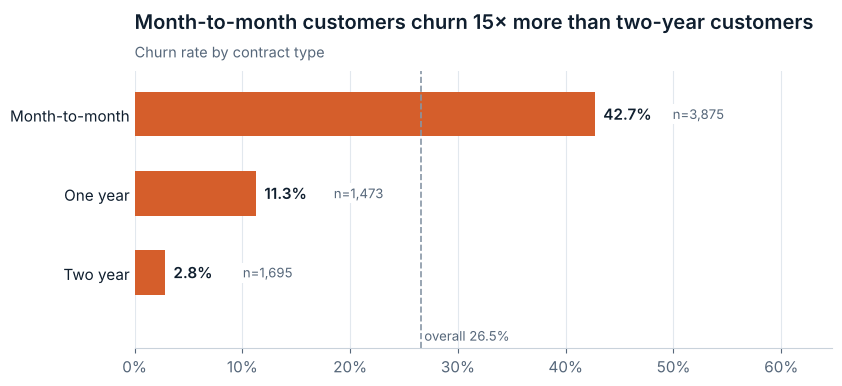

,rate,customers
Contract,,
Two year,0.028319,1695
One year,0.112695,1473
Month-to-month,0.427097,3875


In [7]:
OVERALL = df['churn_flag'].mean()

def rate_table(col, order=None):
    t = df.groupby(col, observed=True)['churn_flag'].agg(rate='mean', customers='size')
    return t.loc[order] if order else t.sort_values('rate')

def rate_bars(ax, t, title=None, subtitle=None):
    y = np.arange(len(t))
    ax.barh(y, t['rate'], height=0.56, color=CHURN)
    ax.set_yticks(y, t.index)
    ax.set_ylim(-0.95, len(t) - 0.45)
    ax.axvline(OVERALL, ls='--', lw=1.2, color=REF)
    ax.text(OVERALL, -0.9, f' overall {OVERALL:.1%}', color=MUTED, fontsize=9.5, va='bottom', ha='left')
    for i, (r, n) in enumerate(zip(t['rate'], t['customers'])):
        ax.annotate(f'{r:.1%}', (r, i), xytext=(6, 0), textcoords='offset points', va='center', fontsize=11, color=INK, fontweight='semibold', bbox=dict(boxstyle='square,pad=0.15', fc='white', ec='none'), zorder=4)
        ax.annotate(f'n={n:,}', (r, i), xytext=(56, 0), textcoords='offset points', va='center', fontsize=9.5, color=MUTED, bbox=dict(boxstyle='square,pad=0.15', fc='white', ec='none'), zorder=4)
    ax.set_xlim(0, t['rate'].max() + 0.22)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis='y', length=0)
    ax.spines['left'].set_visible(False)
    ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
    if title: headline(ax, title, subtitle)

t = rate_table('Contract', ['Two year', 'One year', 'Month-to-month'])
fig, ax = plt.subplots(figsize=(9, 3.6))
rate_bars(ax, t, f"Month-to-month customers churn {t.loc['Month-to-month','rate']/t.loc['Two year','rate']:.0f}× more than two-year customers",
          'Churn rate by contract type')
fig.savefig(IMG + '01_churn_by_contract.png'); plt.show()
t

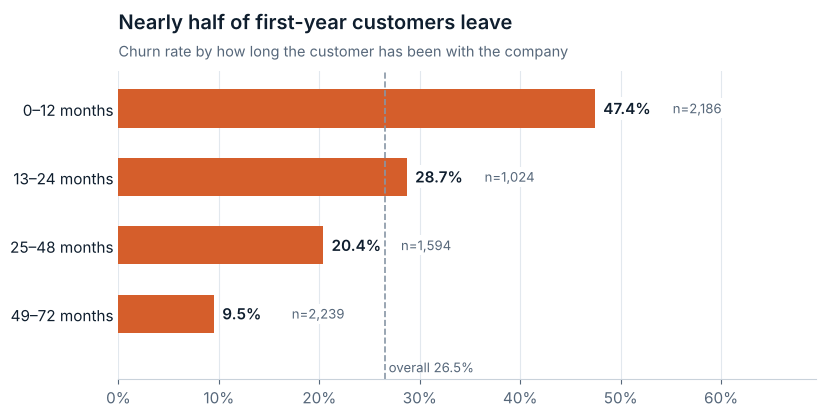

,rate,customers
tenure_band,,
49–72 months,0.095132,2239
25–48 months,0.203890,1594
13–24 months,0.287109,1024
0–12 months,0.474382,2186


In [8]:
order = ['49–72 months', '25–48 months', '13–24 months', '0–12 months']
t = rate_table('tenure_band', order)
fig, ax = plt.subplots(figsize=(9, 4))
rate_bars(ax, t, 'Nearly half of first-year customers leave',
          'Churn rate by how long the customer has been with the company')
fig.savefig(IMG + '02_churn_by_tenure.png'); plt.show()
t

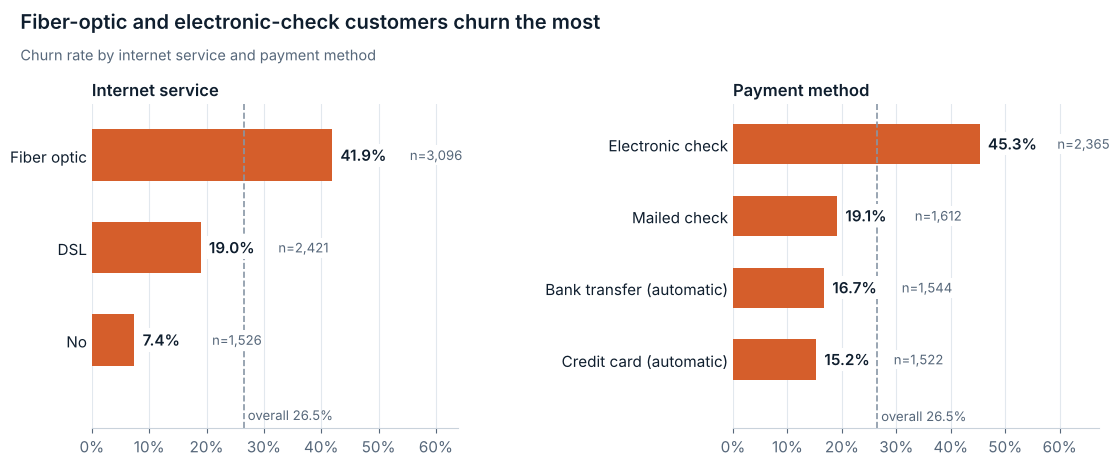

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'wspace': 0.75})
rate_bars(axes[0], rate_table('InternetService', ['No', 'DSL', 'Fiber optic']))
axes[0].set_title('Internet service', loc='left', fontsize=12, fontweight='semibold', color=INK)
rate_bars(axes[1], rate_table('PaymentMethod', ['Credit card (automatic)', 'Bank transfer (automatic)', 'Mailed check', 'Electronic check']))
axes[1].set_title('Payment method', loc='left', fontsize=12, fontweight='semibold', color=INK)
fig.text(0.07, 1.06, 'Fiber-optic and electronic-check customers churn the most', fontsize=14.5, fontweight='semibold', color=INK)
fig.text(0.07, 0.985, 'Churn rate by internet service and payment method', fontsize=10.5, color=MUTED)
fig.savefig(IMG + '03_churn_by_internet_and_payment.png'); plt.show()

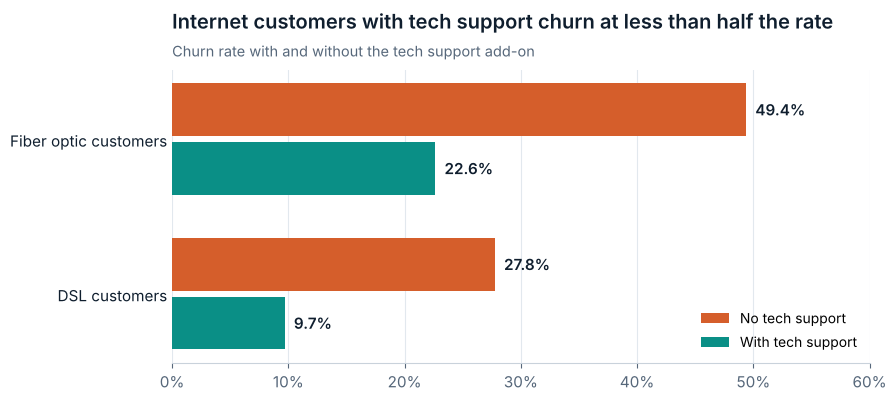

TechSupport,No,Yes
InternetService,,
DSL,0.277554,0.096774
Fiber optic,0.493722,0.226328


In [10]:
net = df[df['InternetService'] != 'No']
t = net.groupby(['InternetService', 'TechSupport'])['churn_flag'].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(t)); h = 0.34
ax.barh(y + h/2 + 0.02, t['No'], height=h, color=CHURN, label='No tech support')
ax.barh(y - h/2 - 0.02, t['Yes'], height=h, color=STAY, label='With tech support')
for i, s in enumerate(t.index):
    ax.text(t.loc[s, 'No'] + 0.008, i + h/2 + 0.02, f"{t.loc[s,'No']:.1%}", va='center', fontsize=11, fontweight='semibold', color=INK)
    ax.text(t.loc[s, 'Yes'] + 0.008, i - h/2 - 0.02, f"{t.loc[s,'Yes']:.1%}", va='center', fontsize=11, fontweight='semibold', color=INK)
ax.set_yticks(y, [f'{s} customers' for s in t.index]); ax.tick_params(axis='y', length=0)
ax.spines['left'].set_visible(False)
ax.set_xlim(0, 0.6); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right', fontsize=10)
headline(ax, 'Internet customers with tech support churn at less than half the rate',
         'Churn rate with and without the tech support add-on')
fig.savefig(IMG + '04_tech_support_effect.png'); plt.show()
t

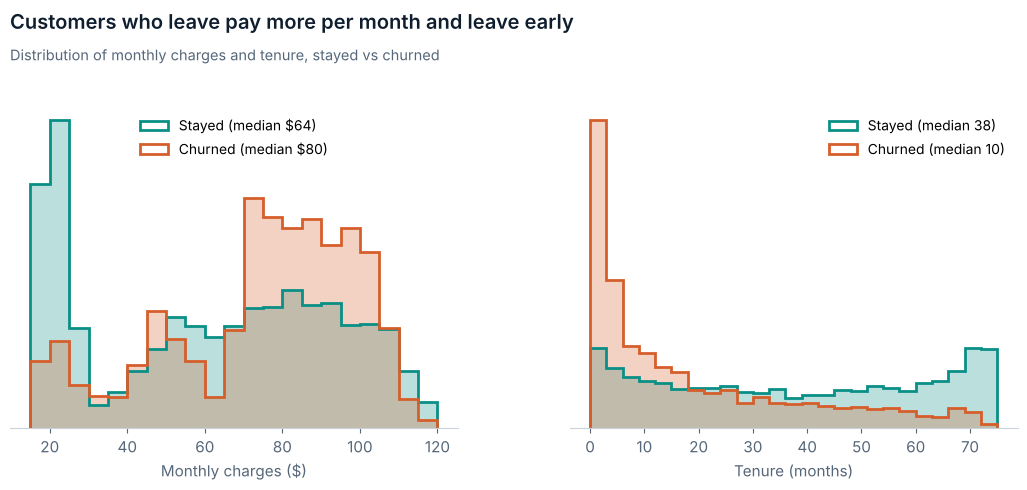

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'wspace': 0.25})
for ax, col, bins, unit, lab in [(axes[0], 'MonthlyCharges', np.arange(15, 125, 5), '$', 'Monthly charges ($)'),
                                 (axes[1], 'tenure', np.arange(0, 76, 3), '', 'Tenure (months)')]:
    for flag, color, name in [(0, STAY, 'Stayed'), (1, CHURN, 'Churned')]:
        vals = df.loc[df['churn_flag'] == flag, col]
        ax.hist(vals, bins=bins, density=True, histtype='stepfilled', alpha=0.28, color=color)
        ax.hist(vals, bins=bins, density=True, histtype='step', lw=2, color=color, label=f'{name} (median {unit}{vals.median():.0f})')
    ax.set_xlabel(lab); ax.set_yticks([]); ax.spines['left'].set_visible(False)
    ax.legend(frameon=False, fontsize=10, loc='upper right' if col == 'tenure' else 'upper center')
fig.text(0.125, 1.06, 'Customers who leave pay more per month and leave early', fontsize=14.5, fontweight='semibold', color=INK)
fig.text(0.125, 0.985, 'Distribution of monthly charges and tenure, stayed vs churned', fontsize=10.5, color=MUTED)
fig.savefig(IMG + '05_charges_and_tenure.png'); plt.show()

**What the exploration shows**
- **Contract** is the clearest divide: month-to-month customers churn at 42.7% versus 2.8% on two-year contracts.
- **The first year is the danger zone:** 47.4% of customers in their first 12 months leave; after four years it drops below 10%.
- **Fiber-optic** customers churn at 41.9% despite paying the most, a sign of a price or service-quality problem worth investigating.
- **Electronic check** payers churn at 45.3%, roughly three times the rate of automatic card or bank payers.
- **Tech support** is associated with less than half the churn rate for both DSL and fiber customers.

These are associations, not proof of cause. Section 6 checks which of them still hold when all factors are considered together.

## 5. How much revenue is at risk?

In [12]:
mrr_total = df['MonthlyCharges'].sum()
mrr_lost = df.loc[df['churn_flag'] == 1, 'MonthlyCharges'].sum()
print(f'Total monthly recurring revenue (MRR): ${mrr_total:,.0f}')
print(f'MRR from customers who churned:        ${mrr_lost:,.0f}  ({mrr_lost/mrr_total:.1%} of MRR)')
print(f'Annualised:                            ${mrr_lost*12:,.0f}')

lost_by_contract = (df[df['churn_flag'] == 1].groupby('Contract')['MonthlyCharges'].sum()
                    .sort_values(ascending=False).to_frame('churned_mrr'))
lost_by_contract['share'] = lost_by_contract['churned_mrr'] / mrr_lost
lost_by_contract.style.format({'churned_mrr': '${:,.0f}', 'share': '{:.1%}'})

Total monthly recurring revenue (MRR): $456,117
MRR from customers who churned:        $139,131  (30.5% of MRR)
Annualised:                            $1,669,570


,churned_mrr,share
Contract,,
Month-to-month,"$120,847",86.9%
One year,"$14,118",10.1%
Two year,"$4,165",3.0%


## 6. Predicting churn risk
**Approach.** A **logistic regression** model estimates each customer's probability of churning from their account details. It was chosen because it is accurate enough for ranking customers *and* easy to explain: each factor gets an odds ratio ("customers with X are N times as likely to churn, all else equal").

**Preparation choices**
- "No internet service" in the six add-on columns is recoded as "No", since `InternetService` already records it (this avoids six copies of the same information).
- `TotalCharges` is left out because it is roughly `tenure × MonthlyCharges` and would blur both effects.
- The data is split 75% training / 25% test, keeping the same churn rate in both (stratified). The model never sees the test customers while learning.

**How to read the scores**
- **ROC AUC:** the chance the model ranks a random churner above a random stayer (0.5 = guessing, 1.0 = perfect).
- **Precision:** of the customers flagged, how many actually churned. **Recall:** of all churners, how many were flagged.

In [13]:
model_df = df.copy()
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for c in addons:
    model_df[c] = model_df[c].replace('No internet service', 'No')
model_df['MultipleLines'] = model_df['MultipleLines'].replace('No phone service', 'No')

X = model_df.drop(columns=['customerID', 'Churn', 'churn_flag', 'TotalCharges', 'tenure_band'])
y = model_df['churn_flag']
numeric = ['tenure', 'MonthlyCharges']
categorical = [c for c in X.columns if c not in numeric]

# Reference (baseline) category for each feature, so odds ratios read "compared with ..."
baseline = {'Contract': 'Two year', 'InternetService': 'No', 'PaymentMethod': 'Credit card (automatic)'}
cats = []
for c in categorical:
    vals = sorted(X[c].unique())
    first = baseline.get(c, 'No' if 'No' in vals else vals[0])
    cats.append([first] + [v for v in vals if v != first])

prep = ColumnTransformer([('num', StandardScaler(), numeric),
                          ('cat', OneHotEncoder(categories=cats, drop='first'), categorical)])
logit = Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=2000))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
logit.fit(X_train, y_train)
p_test = logit.predict_proba(X_test)[:, 1]
pred = (p_test >= 0.5).astype(int)

metrics = {
    'roc_auc': roc_auc_score(y_test, p_test), 'accuracy': accuracy_score(y_test, pred),
    'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred)}
print({k: round(v, 3) for k, v in metrics.items()})
print('Confusion matrix [[stayed predicted stay, stayed predicted churn], [churned predicted stay, churned predicted churn]]:')
print(confusion_matrix(y_test, pred))

{'roc_auc': 0.845, 'accuracy': 0.8, 'precision': 0.645, 'recall': 0.544}
Confusion matrix [[stayed predicted stay, stayed predicted churn], [churned predicted stay, churned predicted churn]]:
[[1154  140]
 [ 213  254]]


In [14]:
# Benchmark: does a more complex model do better?
forest = Pipeline([('prep', prep), ('model', RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=42, n_jobs=-1))])
forest.fit(X_train, y_train)
metrics['forest_auc'] = roc_auc_score(y_test, forest.predict_proba(X_test)[:, 1])
print(f"Logistic regression AUC: {metrics['roc_auc']:.3f}   Random forest AUC: {metrics['forest_auc']:.3f}")

Logistic regression AUC: 0.845   Random forest AUC: 0.844


The random forest does **not** beat the simpler logistic regression, so the interpretable model is kept.

### What drives churn, all else equal?

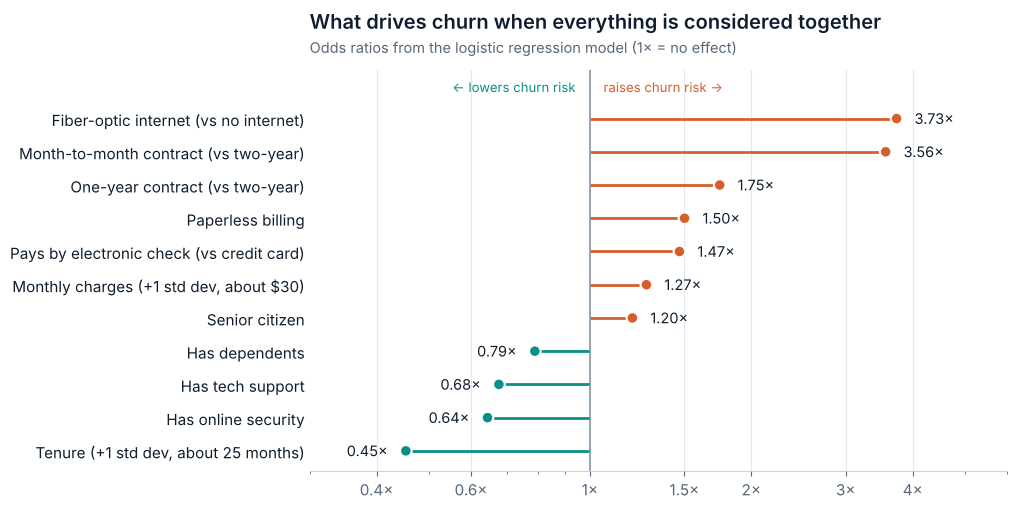

cat__InternetService_Fiber optic                3.73
cat__Contract_Month-to-month                    3.56
cat__InternetService_DSL                        1.88
cat__Contract_One year                          1.75
cat__PaperlessBilling_Yes                       1.50
cat__PaymentMethod_Electronic check             1.47
cat__MultipleLines_Yes                          1.31
num__MonthlyCharges                             1.27
cat__StreamingMovies_Yes                        1.26
cat__SeniorCitizen_Yes                          1.20
cat__StreamingTV_Yes                            1.20
cat__PaymentMethod_Mailed check                 1.16
cat__PaymentMethod_Bank transfer (automatic)    1.03
cat__gender_Male                                1.01
cat__Partner_Yes                                1.00
cat__DeviceProtection_Yes                       0.95
cat__OnlineBackup_Yes                           0.84
cat__Dependents_Yes                             0.79
cat__TechSupport_Yes                          

In [15]:
names = logit.named_steps['prep'].get_feature_names_out()
odds = pd.Series(np.exp(logit.named_steps['model'].coef_[0]), index=names)
labels = {
    'cat__InternetService_Fiber optic': 'Fiber-optic internet (vs no internet)',
    'cat__Contract_Month-to-month': 'Month-to-month contract (vs two-year)',
    'cat__Contract_One year': 'One-year contract (vs two-year)',
    'cat__PaperlessBilling_Yes': 'Paperless billing',
    'cat__PaymentMethod_Electronic check': 'Pays by electronic check (vs credit card)',
    'num__MonthlyCharges': 'Monthly charges (+1 std dev, about $30)',
    'cat__SeniorCitizen_Yes': 'Senior citizen',
    'cat__Dependents_Yes': 'Has dependents',
    'cat__TechSupport_Yes': 'Has tech support',
    'cat__OnlineSecurity_Yes': 'Has online security',
    'num__tenure': 'Tenure (+1 std dev, about 25 months)',
}
plot = odds[list(labels)].rename(labels).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.2))
colors = [CHURN if v > 1 else STAY for v in plot]
ax.hlines(range(len(plot)), 1, plot.values, color=colors, lw=2)
ax.scatter(plot.values, range(len(plot)), s=70, color=colors, zorder=3, edgecolor='white', linewidth=1.5)
ax.axvline(1, color=REF, lw=1.2)
for i, v in enumerate(plot.values):
    ax.text(v * (1.08 if v > 1 else 0.925), i, f'{v:.2f}×', va='center', ha='left' if v > 1 else 'right', fontsize=10.5, color=INK)
ax.set_xscale('log'); ax.set_xticks([0.4, 0.6, 1, 1.5, 2, 3, 4]); ax.get_xaxis().set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}×'))
ax.xaxis.set_minor_formatter(mtick.NullFormatter()); ax.set_xlim(0.3, 6); ax.set_ylim(-0.6, len(plot) + 0.45); ax.set_yticks(range(len(plot)), plot.index); ax.tick_params(axis='y', length=0)
ax.spines['left'].set_visible(False); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.text(1.06, len(plot) - 0.2, 'raises churn risk →', color=CHURN, fontsize=9.5); ax.text(0.94, len(plot) - 0.2, '← lowers churn risk', color=STAY, fontsize=9.5, ha='right')
headline(ax, 'What drives churn when everything is considered together',
         'Odds ratios from the logistic regression model (1× = no effect)')
fig.savefig(IMG + '06_churn_drivers.png'); plt.show()
odds.sort_values(ascending=False).round(2)

### Who should the retention team call first?
Rank test-set customers from highest to lowest predicted risk and count how many actual churners each slice of the list contains.

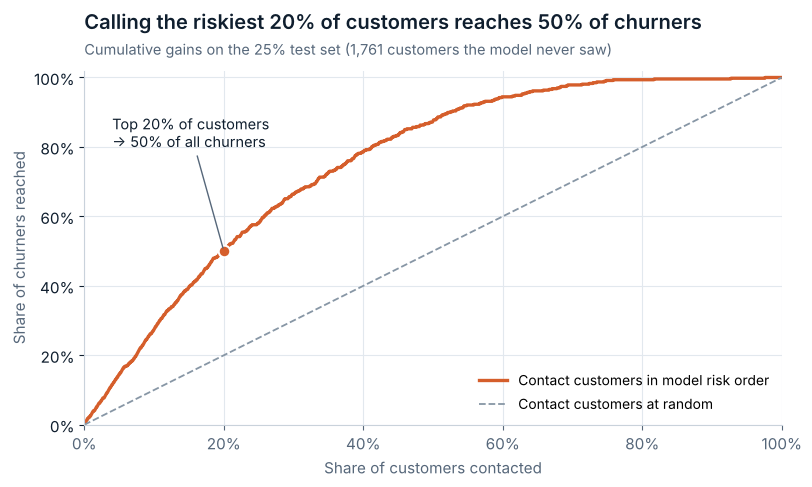

{'capture_top10': 0.274, 'capture_top20': 0.501, 'capture_top30': 0.664}

In [16]:
order = np.argsort(-p_test)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
for f in (0.1, 0.2, 0.3):
    metrics[f'capture_top{int(f*100)}'] = float(captured[int(len(order) * f) - 1])

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(share, captured, color=CHURN, lw=2.4, label='Contact customers in model risk order')
ax.plot([0, 1], [0, 1], ls='--', color=REF, lw=1.3, label='Contact customers at random')
x20, y20 = 0.2, metrics['capture_top20']
ax.scatter([x20], [y20], s=70, color=CHURN, edgecolor='white', linewidth=1.5, zorder=3)
ax.annotate(f'Top 20% of customers\n→ {y20:.0%} of all churners', (x20, y20), xytext=(0.04, 0.80),
            fontsize=10.5, color=INK, arrowprops=dict(arrowstyle='-', color=MUTED, lw=1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel('Share of customers contacted'); ax.set_ylabel('Share of churners reached')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right', fontsize=10)
headline(ax, f'Calling the riskiest 20% of customers reaches {y20:.0%} of churners',
         'Cumulative gains on the 25% test set (1,761 customers the model never saw)')
fig.savefig(IMG + '07_gains_curve.png'); plt.show()
{k: round(v, 3) for k, v in metrics.items() if k.startswith('capture')}

### Risk list for every customer
To score *all* customers fairly, each customer's risk comes from a model trained without them (5-fold cross-validation). Customers are then grouped into risk tiers the retention team can act on.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risk = cross_val_predict(logit, X, y, cv=cv, method='predict_proba')[:, 1]
scores = df[['customerID', 'Contract', 'tenure', 'MonthlyCharges', 'InternetService', 'PaymentMethod', 'Churn']].copy()
scores['churn_risk'] = risk.round(4)
rank = scores['churn_risk'].rank(pct=True, method='first')
scores['risk_tier'] = np.select([rank > 0.8, rank > 0.5], ['High (top 20%)', 'Medium (next 30%)'], 'Low (bottom 50%)')
scores.sort_values('churn_risk', ascending=False).to_csv('../data/customer_risk_scores.csv', index=False)

tiers = scores.groupby('risk_tier').agg(customers=('customerID', 'size'),
                                        actual_churn_rate=('Churn', lambda s: (s == 'Yes').mean()),
                                        monthly_revenue=('MonthlyCharges', 'sum'))
tiers = tiers.loc[['High (top 20%)', 'Medium (next 30%)', 'Low (bottom 50%)']]
metrics['cv_auc'] = roc_auc_score(y, risk)
metrics['high_tier_churn'] = float(tiers.loc['High (top 20%)', 'actual_churn_rate'])
metrics['high_tier_mrr'] = float(tiers.loc['High (top 20%)', 'monthly_revenue'])
metrics.update({'overall_churn': float(OVERALL), 'mrr_total': float(mrr_total), 'mrr_lost': float(mrr_lost)})
json.dump({k: float(v) for k, v in metrics.items()}, open('../data/summary_metrics.json', 'w'), indent=2)
print(f"Cross-validated AUC across all customers: {metrics['cv_auc']:.3f}")
tiers.style.format({'actual_churn_rate': '{:.1%}', 'monthly_revenue': '${:,.0f}', 'customers': '{:,}'})

Cross-validated AUC across all customers: 0.843


,customers,actual_churn_rate,monthly_revenue
risk_tier,,,
High (top 20%),"1,409",67.6%,"$115,981"
Medium (next 30%),"2,113",31.8%,"$141,724"
Low (bottom 50%),"3,521",7.0%,"$198,411"


## 7. Recommendations
**The cost of churn:** customers who left took **$139,131 of monthly recurring revenue** with them, **30.5%** of the total, or about **$1.67 million a year**.

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Move month-to-month customers onto contracts.** Offer a discount or perk for switching to a one-year contract, starting with high-risk month-to-month customers. | 42.7% churn on month-to-month vs 2.8% on two-year; 3.6× the odds even after accounting for everything else. |
| 2 | **Fix the first year.** Structured onboarding: a welcome call, check-ins at months 1, 3 and 6, and fast resolution of early service problems. | 47.4% of customers in their first 12 months leave; median tenure of churners is 10 months vs 38 for those who stay. |
| 3 | **Investigate the fiber-optic service.** Review fiber pricing, reliability and competitor offers, and survey customers who left. | Fiber customers churn at 41.9% despite paying the most; 3.7× the odds of customers without internet. |
| 4 | **Bundle tech support and online security.** Give new internet customers a free trial and test (A/B) whether it reduces churn. | Fiber customers without tech support churn at 49.4% vs 22.6% with it; both add-ons are linked to lower odds (0.68× and 0.64×). |
| 5 | **Move electronic-check payers to automatic payment.** A small incentive to switch to debit order or card auto-pay. | 45.3% churn for electronic check vs 15–17% for automatic payments; 1.5× the odds. |
| 6 | **Run the risk model every month.** Give the retention team the high-risk list (`data/customer_risk_scores.csv`). | The riskiest 20% of customers include 50% of all churners; 67.6% of them actually churned, and they hold $115,981 of monthly revenue. |

## 8. Limitations
- **Fictional sample data.** IBM's dataset describes a made-up company; the patterns are realistic but the numbers should not be quoted as industry benchmarks.
- **One snapshot.** Churn is recorded for a single month with no history, so seasonality and changes over time cannot be studied.
- **Association, not causation.** The model shows which customers are more likely to leave, not that changing one factor (e.g. adding tech support) will by itself keep them. Retention offers should be tested (A/B test) before full rollout.
- **No cost data.** Without the cost of retention offers or customer acquisition, the return on each recommendation cannot be calculated yet.
- **Threshold choice.** At a 0.5 probability cut-off the model favours precision; a retention team that prefers to reach more churners can lower the threshold, accepting more false alarms.

## 9. Files
| File | Contents |
|---|---|
| `data/Telco-Customer-Churn.csv` | Original IBM dataset |
| `data/telco_churn_clean.csv` | Cleaned data with churn flag and tenure bands (ready for Power BI / Excel) |
| `data/customer_risk_scores.csv` | Churn risk score and tier for every customer |
| `sql/churn_analysis_queries.sql` | SQL versions of the key analysis queries |
| `images/` | All charts in this notebook |